<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_4_Tree_Based_Methods/Projects/Instructions/Project.4-Spotify/Spotify_Pass_07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Spotify Pass 01

In [48]:
! curl -s -I https://ddc-datascience.s3.amazonaws.com/Projects/Project.4-Spotify/Data/Spotify.csv

HTTP/1.1 200 OK
x-amz-id-2: v8j2dRNurZKlecmi46ziRsSEedBpXqphP/YpKE6TDNwgk7WKheF0/v4iprw+NURYJ+GYqa3y3CJEYug2vUTApjl7YS9zdFx/
x-amz-request-id: HRXWNABH5VG6CCWF
Server: AmazonS3
Date: Mon, 23 Nov 2026 03:48:48 GMT
Last-Modified: Wed, 04 Oct 2023 17:23:56 GMT
ETag: "65b9875b11e0d7ea03ee2af024f45e99"
x-amz-server-side-encryption: AES256
Accept-Ranges: bytes
Content-Length: 738124
Content-Type: text/csv



In [49]:
! curl -s https://ddc-datascience.s3.amazonaws.com/Projects/Project.4-Spotify/Data/Spotify.csv | head -2

Index,Highest Charting Position,Number of Times Charted,Week of Highest Charting,Song Name,Streams,Artist,Artist Followers,Song ID,Genre,Release Date,Weeks Charted,Popularity,Danceability,Energy,Loudness,Speechiness,Acousticness,Liveness,Tempo,Duration (ms),Valence,Chord
1,1,8,2021-07-23--2021-07-30,Beggin',"48,633,449",Måneskin,3377762,3Wrjm47oTz2sjIgck11l5e,"['indie rock italiano', 'italian pop']",2017-12-08,"2021-07-23--2021-07-30


## Data Collection/Sources

### Load Modules

In [50]:
%%writefile metadata.py
import pandas as pd

def metadata(dataframe):
  '''Given a dataframe, returns a dataframe of metadata about the dataframe'''
  # Guard against duplicate column names in the input dataframe
  dataframe = dataframe.loc[:, ~dataframe.columns.duplicated()].copy()

  metadata_df = pd.DataFrame(index=dataframe.columns)
  metadata_df["Data_types"] = dataframe.dtypes
  metadata_df["Count"] = len(dataframe)
  metadata_df["Nulls"] = dataframe.isnull().sum()
  metadata_df["Nulls_pct"] = (metadata_df["Nulls"] / metadata_df["Count"] * 100).round(1)
  metadata_df["Memory"] = dataframe.memory_usage(deep=True, index=False)
  metadata_df["NUnique"] = dataframe.nunique()
  metadata_df["NUnique_pct"] = (dataframe.nunique() / metadata_df["Count"] * 100).round(1)

  desc = dataframe.describe(include="all").transpose()
  # Drop lowercase 'count' from describe() since 'Count' already exists
  desc = desc.drop(columns=["count"], errors="ignore")
  metadata_df = metadata_df.join(desc)

  if dataframe.select_dtypes(include=['number']).shape[1]:
    for col in ["25%", "50%", "75%", "min", "max", "mean"]:
      if col in metadata_df.columns:
        metadata_df[col] = pd.to_numeric(metadata_df[col], errors="coerce")

    metadata_df["IQR"] = metadata_df["75%"] - metadata_df["25%"]
    metadata_df["range"] = metadata_df["max"] - metadata_df["min"]
    metadata_df["sum"] = metadata_df["mean"] * (metadata_df["Count"] - metadata_df["Nulls"])
    metadata_df = metadata_df.rename(
        columns={
            "25%": "Q1_25%",
            "50%": "Q2_median",
            "75%": "Q3_75%",
        }
    )
  return metadata_df

Overwriting metadata.py


In [77]:
# Import the libraries and modules
import metadata as md

from IPython.display import Image

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
import statsmodels.api as sm

from sklearn import datasets, metrics, model_selection
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor


### Load Data

In [52]:
# Define the data's url as 'url'
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.4-Spotify/Data/Spotify.csv'    # insert url here
url

'https://ddc-datascience.s3.amazonaws.com/Projects/Project.4-Spotify/Data/Spotify.csv'

In [53]:
# Define the data frame as 'df'
df = pd.read_csv(url)

## Data Cleaning

### Overview

In [54]:
# Display the head
df.head()

,Index,Highest Charting Position,Number of Times Charted,Week of Highest Charting,Song Name,Streams,Artist,Artist Followers,Song ID,Genre,...,Danceability,Energy,Loudness,Speechiness,Acousticness,Liveness,Tempo,Duration (ms),Valence,Chord
0,1,1,8,2021-07-23--2021-07-30,Beggin',"48,633,449",Måneskin,3377762,3Wrjm47oTz2sjIgck11l5e,"['indie rock italiano', 'italian pop']",...,0.714,0.8,-4.808,0.0504,0.127,0.359,134.002,211560,0.589,B
1,2,2,3,2021-07-23--2021-07-30,STAY (with Justin Bieber),"47,248,719",The Kid LAROI,2230022,5HCyWlXZPP0y6Gqq8TgA20,['australian hip hop'],...,0.591,0.764,-5.484,0.0483,0.0383,0.103,169.928,141806,0.478,C#/Db
2,3,1,11,2021-06-25--2021-07-02,good 4 u,"40,162,559",Olivia Rodrigo,6266514,4ZtFanR9U6ndgddUvNcjcG,['pop'],...,0.563,0.664,-5.044,0.154,0.335,0.0849,166.928,178147,0.688,A
3,4,3,5,2021-07-02--2021-07-09,Bad Habits,"37,799,456",Ed Sheeran,83293380,6PQ88X9TkUIAUIZJHW2upE,"['pop', 'uk pop']",...,0.808,0.897,-3.712,0.0348,0.0469,0.364,126.026,231041,0.591,B
4,5,5,1,2021-07-23--2021-07-30,INDUSTRY BABY (feat. Jack Harlow),"33,948,454",Lil Nas X,5473565,27NovPIUIRrOZoCHxABJwK,"['lgbtq+ hip hop', 'pop rap']",...,0.736,0.704,-7.409,0.0615,0.0203,0.0501,149.995,212000,0.894,D#/Eb


In [55]:
# Display the tail
df.tail()

,Index,Highest Charting Position,Number of Times Charted,Week of Highest Charting,Song Name,Streams,Artist,Artist Followers,Song ID,Genre,...,Danceability,Energy,Loudness,Speechiness,Acousticness,Liveness,Tempo,Duration (ms),Valence,Chord
1551,1552,195,1,2019-12-27--2020-01-03,New Rules,"4,630,675",Dua Lipa,27167675,2ekn2ttSfGqwhhate0LSR0,"['dance pop', 'pop', 'uk pop']",...,0.762,0.7,-6.021,0.0694,0.00261,0.153,116.073,209320,0.608,A
1552,1553,196,1,2019-12-27--2020-01-03,Cheirosa - Ao Vivo,"4,623,030",Jorge & Mateus,15019109,2PWjKmjyTZeDpmOUa3a5da,"['sertanejo', 'sertanejo universitario']",...,0.528,0.87,-3.123,0.0851,0.24,0.333,152.37,181930,0.714,B
1553,1554,197,1,2019-12-27--2020-01-03,Havana (feat. Young Thug),"4,620,876",Camila Cabello,22698747,1rfofaqEpACxVEHIZBJe6W,"['dance pop', 'electropop', 'pop', 'post-teen ...",...,0.765,0.523,-4.333,0.03,0.184,0.132,104.988,217307,0.394,D
1554,1555,198,1,2019-12-27--2020-01-03,Surtada - Remix Brega Funk,"4,607,385","Dadá Boladão, Tati Zaqui, OIK",208630,5F8ffc8KWKNawllr5WsW0r,"['brega funk', 'funk carioca']",...,0.832,0.55,-7.026,0.0587,0.249,0.182,154.064,152784,0.881,F
1555,1556,199,1,2019-12-27--2020-01-03,Lover (Remix) [feat. Shawn Mendes],"4,595,450",Taylor Swift,42227614,3i9UVldZOE0aD0JnyfAZZ0,"['pop', 'post-teen pop']",...,0.448,0.603,-7.176,0.064,0.433,0.0862,205.272,221307,0.422,G


In [56]:
# See the shape
df.shape

(1556, 23)

In [57]:
# See how many total entries
df.size

35788

In [58]:
df.columns

Index(['Index', 'Highest Charting Position', 'Number of Times Charted',
       'Week of Highest Charting', 'Song Name', 'Streams', 'Artist',
       'Artist Followers', 'Song ID', 'Genre', 'Release Date', 'Weeks Charted',
       'Popularity', 'Danceability', 'Energy', 'Loudness', 'Speechiness',
       'Acousticness', 'Liveness', 'Tempo', 'Duration (ms)', 'Valence',
       'Chord'],
      dtype='object')

### Summary Statistics

Summary statistics give you a quick overview of the data.  Some items to spot check:
- the Target:
  - look for nulls
    - null will be culled
  - look at min, max, median, and mean
    - is it a categorical field masquerading as a number?
- the Features:
  - numerical
    - look at min, max, median, and mean
      - a min=1 and max=count suggests an ID
  - categorical
    - look at unique and freq
      - freq=1, unique=count suggests an ID
      - freq=count suggests a meaningless feature

In [59]:
# Summary meta-data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1556 entries, 0 to 1555
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Index                      1556 non-null   int64 
 1   Highest Charting Position  1556 non-null   int64 
 2   Number of Times Charted    1556 non-null   int64 
 3   Week of Highest Charting   1556 non-null   object
 4   Song Name                  1556 non-null   object
 5   Streams                    1556 non-null   object
 6   Artist                     1556 non-null   object
 7   Artist Followers           1556 non-null   object
 8   Song ID                    1556 non-null   object
 9   Genre                      1556 non-null   object
 10  Release Date               1556 non-null   object
 11  Weeks Charted              1556 non-null   object
 12  Popularity                 1556 non-null   object
 13  Danceability               1556 non-null   object
 14  Energy  

In [60]:
# See the summary statistics
md.metadata(df)

,Data_types,Count,Nulls,Nulls_pct,Memory,NUnique,NUnique_pct,unique,top,freq,mean,std,min,Q1_25%,Q2_median,Q3_75%,max,IQR,range,sum
Index,int64,1556,0,0.0,12448,1556,100.0,NaN,NaN,NaN,778.500000,449.322824,1.0,389.75,778.5,1167.25,1556.0,777.5,1555.0,1211346.0
Highest Charting Position,int64,1556,0,0.0,12448,200,12.9,NaN,NaN,NaN,87.744216,58.147225,1.0,37.00,80.0,137.00,200.0,100.0,199.0,136530.0
Number of Times Charted,int64,1556,0,0.0,12448,75,4.8,NaN,NaN,NaN,10.668380,16.360546,1.0,1.00,4.0,12.00,142.0,11.0,141.0,16600.0
Week of Highest Charting,object,1556,0,0.0,110476,83,5.3,83,2019-12-27--2020-01-03,89,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Song Name,object,1556,0,0.0,107813,1556,100.0,1556,Beggin',1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Streams,object,1556,0,0.0,90353,1556,100.0,1556,"48,633,449",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Artist,object,1556,0,0.0,98048,716,46.0,716,Taylor Swift,52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Artist Followers,object,1556,0,0.0,87449,600,38.6,600,42227614,52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Song ID,object,1556,0,0.0,110245,1517,97.5,1517,,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Genre,object,1556,0,0.0,136772,395,25.4,395,[],75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Nulls & Identifier Columns

#### Target Nulls


The target should be the first field that you look at.  Its data type will tell you what kind of machine learning problem this is ( classification or regression. ) Any nulls should be culled.  You can check for any skew in the data set.

In [61]:
# Define the name of the target column 'SalePrice' to work with it independently
target_col = 'Popularity'
target = df[target_col]
target

,Popularity
0,100
1,99
2,99
3,98
4,96
...,...
1551,79
1552,66
1553,81
1554,60


In [62]:
# Look for nulls in the target
df[target_col].isnull().sum() / df[target_col].shape[0] * 100


np.float64(0.0)

#### Feature Nulls

In [63]:
# Define the name of the feature columns to work with them independently

# Drop the target column from the feature column names
feature_cols = df.drop(columns=target_col, errors='ignore')

feature_cols.dtypes

,0
Index,int64
Highest Charting Position,int64
Number of Times Charted,int64
Week of Highest Charting,object
Song Name,object
Streams,object
Artist,object
Artist Followers,object
Song ID,object
Genre,object


In [64]:
# Look for nulls in the features
(feature_cols.isnull().sum() / feature_cols.shape[0] * 100).sort_values(ascending=False)

,0
Index,0.0
Highest Charting Position,0.0
Number of Times Charted,0.0
Week of Highest Charting,0.0
Song Name,0.0
Streams,0.0
Artist,0.0
Artist Followers,0.0
Song ID,0.0
Genre,0.0


In [65]:
feature_cols

,Index,Highest Charting Position,Number of Times Charted,Week of Highest Charting,Song Name,Streams,Artist,Artist Followers,Song ID,Genre,...,Danceability,Energy,Loudness,Speechiness,Acousticness,Liveness,Tempo,Duration (ms),Valence,Chord
0,1,1,8,2021-07-23--2021-07-30,Beggin',"48,633,449",Måneskin,3377762,3Wrjm47oTz2sjIgck11l5e,"['indie rock italiano', 'italian pop']",...,0.714,0.8,-4.808,0.0504,0.127,0.359,134.002,211560,0.589,B
1,2,2,3,2021-07-23--2021-07-30,STAY (with Justin Bieber),"47,248,719",The Kid LAROI,2230022,5HCyWlXZPP0y6Gqq8TgA20,['australian hip hop'],...,0.591,0.764,-5.484,0.0483,0.0383,0.103,169.928,141806,0.478,C#/Db
2,3,1,11,2021-06-25--2021-07-02,good 4 u,"40,162,559",Olivia Rodrigo,6266514,4ZtFanR9U6ndgddUvNcjcG,['pop'],...,0.563,0.664,-5.044,0.154,0.335,0.0849,166.928,178147,0.688,A
3,4,3,5,2021-07-02--2021-07-09,Bad Habits,"37,799,456",Ed Sheeran,83293380,6PQ88X9TkUIAUIZJHW2upE,"['pop', 'uk pop']",...,0.808,0.897,-3.712,0.0348,0.0469,0.364,126.026,231041,0.591,B
4,5,5,1,2021-07-23--2021-07-30,INDUSTRY BABY (feat. Jack Harlow),"33,948,454",Lil Nas X,5473565,27NovPIUIRrOZoCHxABJwK,"['lgbtq+ hip hop', 'pop rap']",...,0.736,0.704,-7.409,0.0615,0.0203,0.0501,149.995,212000,0.894,D#/Eb
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1551,1552,195,1,2019-12-27--2020-01-03,New Rules,"4,630,675",Dua Lipa,27167675,2ekn2ttSfGqwhhate0LSR0,"['dance pop', 'pop', 'uk pop']",...,0.762,0.7,-6.021,0.0694,0.00261,0.153,116.073,209320,0.608,A
1552,1553,196,1,2019-12-27--2020-01-03,Cheirosa - Ao Vivo,"4,623,030",Jorge & Mateus,15019109,2PWjKmjyTZeDpmOUa3a5da,"['sertanejo', 'sertanejo universitario']",...,0.528,0.87,-3.123,0.0851,0.24,0.333,152.37,181930,0.714,B
1553,1554,197,1,2019-12-27--2020-01-03,Havana (feat. Young Thug),"4,620,876",Camila Cabello,22698747,1rfofaqEpACxVEHIZBJe6W,"['dance pop', 'electropop', 'pop', 'post-teen ...",...,0.765,0.523,-4.333,0.03,0.184,0.132,104.988,217307,0.394,D
1554,1555,198,1,2019-12-27--2020-01-03,Surtada - Remix Brega Funk,"4,607,385","Dadá Boladão, Tati Zaqui, OIK",208630,5F8ffc8KWKNawllr5WsW0r,"['brega funk', 'funk carioca']",...,0.832,0.55,-7.026,0.0587,0.249,0.182,154.064,152784,0.881,F


#### Identifier Columns

In [66]:
# See proportion of unique values in the target column
(df[target_col].nunique() / df[target_col].shape[0] * 100) #.sort_values(ascending=False)

4.4987146529562985

In [67]:
# See proportion of unique values in the feature columns - highest is 1%
(feature_cols.nunique() / feature_cols.shape[0] * 100).sort_values(ascending=False)

,0
Index,100.000000
Streams,100.000000
Song Name,100.000000
Song ID,97.493573
Duration (ms),95.501285
Tempo,93.894602
Loudness,89.588689
Acousticness,62.017995
Weeks Charted,49.807198
Speechiness,49.614396


### Backup #1

In [68]:
# Make a backup
df_bak1 = df.copy()

In [69]:
# Restore from backup
df = df_bak1.copy()

### Cull the Nulls

If equal to or greater than 90%, dropped columns.

If between 20-89%, imputed with the mode.

If between 0-19%, dropped the rows.

In [70]:
# Calculate the percentage of nulls in each feature column
null_percent = (feature_cols.isnull().sum() / df.shape[0] * 100).sort_values(ascending=False)

null_percent

,0
Index,0.0
Highest Charting Position,0.0
Number of Times Charted,0.0
Week of Highest Charting,0.0
Song Name,0.0
Streams,0.0
Artist,0.0
Artist Followers,0.0
Song ID,0.0
Genre,0.0


### Drop Identifier Column

In [71]:
# Drop the identifier columns
id_col = ['Song ID', 'Song Name', 'Index'
]
feature_cols = [col for col in feature_cols if col not in id_col]

In [72]:
# Verify identifier column dropped
df[feature_cols].shape

(1556, 19)

### Backup #2

In [73]:
# Make a backup
df_bak2 = df.copy()

In [74]:
# Restore from backup
df = df_bak2.copy()

### Cleaned Data Frame

In [75]:
# Define our target and feature columns as a data frame to work with 'df_clean'
df_clean = pd.concat([df[target_col], df[feature_cols]], axis=1).reset_index(drop=True)

In [76]:
# Verify the working data frame
df_clean

,Popularity,Highest Charting Position,Number of Times Charted,Week of Highest Charting,Streams,Artist,Artist Followers,Genre,Release Date,Weeks Charted,Danceability,Energy,Loudness,Speechiness,Acousticness,Liveness,Tempo,Duration (ms),Valence,Chord
0,100,1,8,2021-07-23--2021-07-30,"48,633,449",Måneskin,3377762,"['indie rock italiano', 'italian pop']",2017-12-08,2021-07-23--2021-07-30\n2021-07-16--2021-07-23...,0.714,0.8,-4.808,0.0504,0.127,0.359,134.002,211560,0.589,B
1,99,2,3,2021-07-23--2021-07-30,"47,248,719",The Kid LAROI,2230022,['australian hip hop'],2021-07-09,2021-07-23--2021-07-30\n2021-07-16--2021-07-23...,0.591,0.764,-5.484,0.0483,0.0383,0.103,169.928,141806,0.478,C#/Db
2,99,1,11,2021-06-25--2021-07-02,"40,162,559",Olivia Rodrigo,6266514,['pop'],2021-05-21,2021-07-23--2021-07-30\n2021-07-16--2021-07-23...,0.563,0.664,-5.044,0.154,0.335,0.0849,166.928,178147,0.688,A
3,98,3,5,2021-07-02--2021-07-09,"37,799,456",Ed Sheeran,83293380,"['pop', 'uk pop']",2021-06-25,2021-07-23--2021-07-30\n2021-07-16--2021-07-23...,0.808,0.897,-3.712,0.0348,0.0469,0.364,126.026,231041,0.591,B
4,96,5,1,2021-07-23--2021-07-30,"33,948,454",Lil Nas X,5473565,"['lgbtq+ hip hop', 'pop rap']",2021-07-23,2021-07-23--2021-07-30,0.736,0.704,-7.409,0.0615,0.0203,0.0501,149.995,212000,0.894,D#/Eb
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1551,79,195,1,2019-12-27--2020-01-03,"4,630,675",Dua Lipa,27167675,"['dance pop', 'pop', 'uk pop']",2017-06-02,2019-12-27--2020-01-03,0.762,0.7,-6.021,0.0694,0.00261,0.153,116.073,209320,0.608,A
1552,66,196,1,2019-12-27--2020-01-03,"4,623,030",Jorge & Mateus,15019109,"['sertanejo', 'sertanejo universitario']",2019-10-11,2019-12-27--2020-01-03,0.528,0.87,-3.123,0.0851,0.24,0.333,152.37,181930,0.714,B
1553,81,197,1,2019-12-27--2020-01-03,"4,620,876",Camila Cabello,22698747,"['dance pop', 'electropop', 'pop', 'post-teen ...",2018-01-12,2019-12-27--2020-01-03,0.765,0.523,-4.333,0.03,0.184,0.132,104.988,217307,0.394,D
1554,60,198,1,2019-12-27--2020-01-03,"4,607,385","Dadá Boladão, Tati Zaqui, OIK",208630,"['brega funk', 'funk carioca']",2019-09-25,2019-12-27--2020-01-03,0.832,0.55,-7.026,0.0587,0.249,0.182,154.064,152784,0.881,F


## EDA & Data Processing

### Decision Tree Regression

In [78]:
# 1. Select target and chosen features
cols = ['Popularity', 'Danceability', 'Energy', 'Tempo', 'Streams']
df_tree = df_clean[cols].copy()

# 2. Strip commas from Streams and convert all 5 columns to numeric
df_tree['Streams'] = df_tree['Streams'].str.replace(',', '', regex=False)
for col in cols:
    df_tree[col] = pd.to_numeric(df_tree[col], errors='coerce')

# 3. Drop the 11 rows with missing values
df_tree = df_tree.dropna().reset_index(drop=True)

# 4. Split features and target
X = df_tree[['Danceability', 'Energy', 'Tempo', 'Streams']]
y = df_tree['Popularity']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# 5. Fit and evaluate the Decision Tree Regressor
# Setting max_depth prevents the tree from memorizing every song (overfitting)
dt_reg = DecisionTreeRegressor(max_depth=5, random_state=42)
dt_reg.fit(X_train, y_train)

y_pred = dt_reg.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Test RMSE: {rmse:.2f}")

Test RMSE: 17.10


## Data Visualization

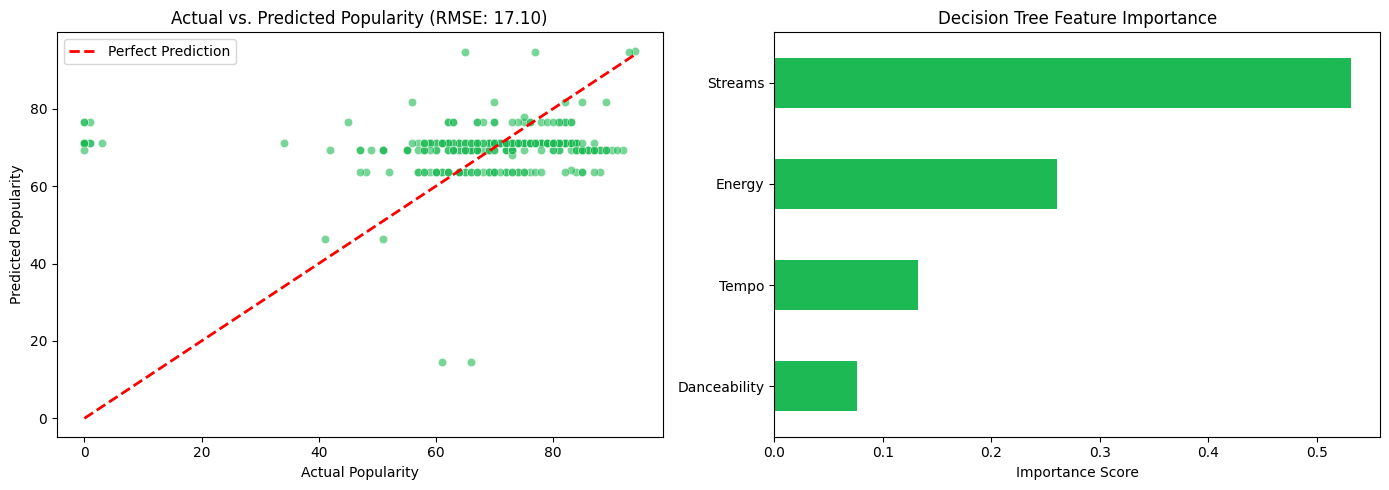

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Actual vs. Predicted Popularity
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, ax=axes[0], color='#1DB954')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction')
axes[0].set_title(f'Actual vs. Predicted Popularity (RMSE: {rmse:.2f})')
axes[0].set_xlabel('Actual Popularity')
axes[0].set_ylabel('Predicted Popularity')
axes[0].legend()

# Plot 2: Feature Importance
importances = pd.Series(dt_reg.feature_importances_, index=X.columns).sort_values(ascending=True)
importances.plot(kind='barh', ax=axes[1], color='#1DB954')
axes[1].set_title('Decision Tree Feature Importance')
axes[1].set_xlabel('Importance Score')

plt.tight_layout()
plt.show()

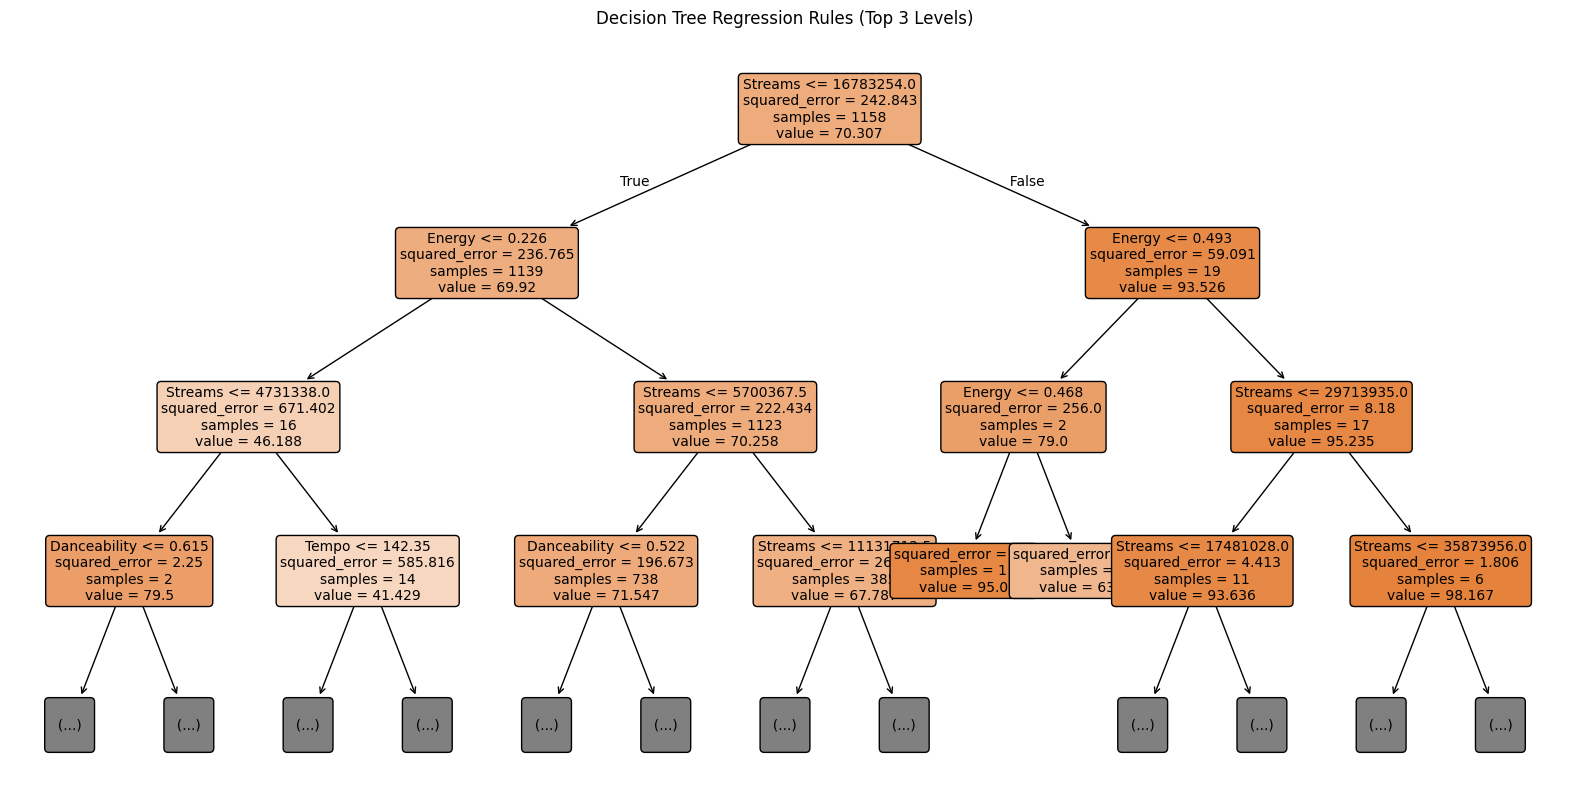

In [82]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(
    dt_reg,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    max_depth=3,  # Shows top 3 levels so text remains readable
    fontsize=10
)
plt.title('Decision Tree Regression Rules (Top 3 Levels)')
plt.show()

## Communication of Results

#### Conclusion

#### Future Work
